In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


In [1]:
# ============================================================
# PHÂN TÍCH DỮ LIỆU DGA (DOMAIN GENERATION ALGORITHM) - ĐƠN GIẢN HÓA
# ============================================================

# 1. Import thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.preprocessing import StandardScaler
from pathlib import Path

In [2]:
# 2. Load dữ liệu
root_folder = Path.cwd()
data = np.load(root_folder / "Dataset" / "1000_dga_dataset_binary.npz", allow_pickle=True)

X = data["X"]               # Mảng các domain đã được mã hóa
y = data["y"]               # Nhãn: 0 = Benign, 1 = DGA
char2idx = data["char2idx"].item()
max_length = int(data["max_length"])

print(f"Kích thước dữ liệu: X={X.shape}, y={y.shape}")
print(f"Số lượng mỗi lớp: Benign={sum(y==0)}, DGA={sum(y==1)}")
print("5 mẫu đầu tiên của X:")
print(X[:5])

print("\n5 nhãn đầu tiên:")
print(y[:5])

Kích thước dữ liệu: X=(2000, 75), y=(2000,)
Số lượng mỗi lớp: Benign=1000, DGA=1000
5 mẫu đầu tiên của X:
[[53 44 62 52 40 57 50 44 59 47 54 51 48 43 40 64 58  2 42 54  2 60 50  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [52 54 58  8 61  6  7 45 50  2 41 48 65  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [46 40 41 57 48 44 51 51 44 52 54 53 59 46 54 52 44 57 64  2 53 44 59  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [52 40 55 44 48  2 46 57 54 60 55  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0 

In [29]:
# 3. Chuyển index thành domain string
idx2char = {v: k for k, v in char2idx.items()}
domains = []
for row in X:
    text = "".join(idx2char[idx] for idx in row if idx != 0 and idx in idx2char)
    domains.append(text)

In [30]:
# 4. Tạo DataFrame
df = pd.DataFrame({"domain": domains, "label": y})
df["label_name"] = df["label"].map({0: "Benign", 1: "DGA"})

In [31]:
# 5. Feature Engineering
def count_digits(s): return sum(c.isdigit() for c in s)
def count_vowels(s): return sum(c in "aeiou" for c in s.lower())
def count_special(s): return sum(c in "-_" for c in s)
def entropy(s):
    prob = [s.count(c)/len(s) for c in set(s)]
    return -sum(p * np.log2(p) for p in prob)

df["length"] = df["domain"].apply(len)
df["digits"] = df["domain"].apply(count_digits)
df["vowels"] = df["domain"].apply(count_vowels)
df["special_chars"] = df["domain"].apply(count_special)
df["digit_ratio"] = df["digits"] / (df["length"] + 1e-5)
df["vowel_ratio"] = df["vowels"] / (df["length"] + 1e-5)
df["entropy"] = df["domain"].apply(entropy)

feature_cols = ["length", "digits", "vowels", "special_chars", "digit_ratio", "vowel_ratio", "entropy"]
print("\n5 dòng đầu tiên sau khi thêm đặc trưng:")
print(df.head())


5 dòng đầu tiên sau khi thêm đặc trưng:
                    domain  label label_name  length  digits  vowels  \
0  newmarketholidays.co.uk      0     Benign      23       0       8   
1            mos5v34fk.biz      1        DGA      13       3       2   
2  gabriellemontgomery.net      1        DGA      23       0       8   
3              mapei.group      0     Benign      11       0       5   
4             chinaedu.net      0     Benign      12       0       5   

   special_chars  digit_ratio  vowel_ratio   entropy  
0              0     0.000000     0.347826  4.088779  
1              0     0.230769     0.153846  3.700440  
2              0     0.000000     0.347826  3.567040  
3              0     0.000000     0.454545  3.277613  
4              0     0.000000     0.416666  3.251629  


In [32]:
# 6. Chuẩn hóa dữ liệu
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[feature_cols] = scaler.fit_transform(df[feature_cols])

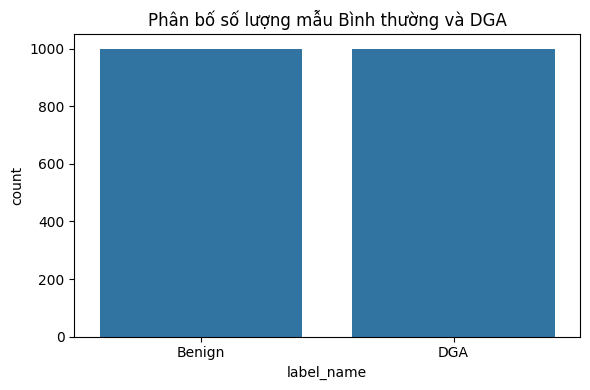

In [33]:
# 7. Trực quan hóa phân bố nhãn
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="label_name")
plt.title("Phân bố số lượng mẫu Bình thường và DGA")
plt.tight_layout()
plt.show()

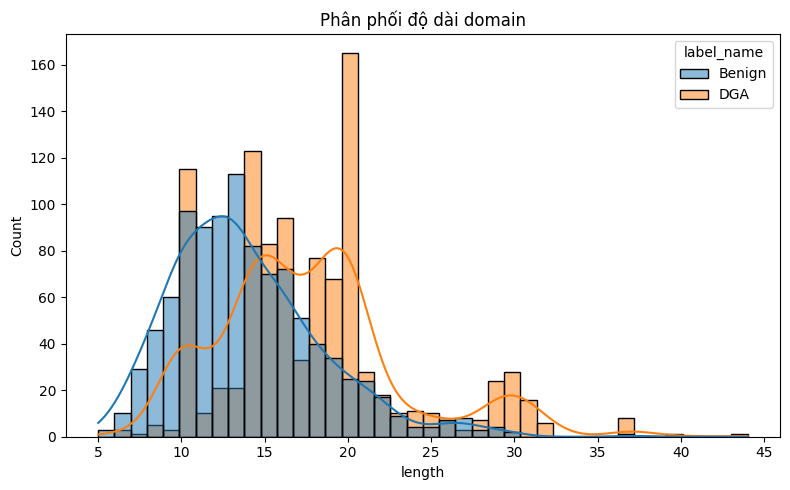

In [34]:
# 8. So sánh độ dài domain giữa hai loại
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="length", hue="label_name", bins=40, kde=True)
plt.title("Phân phối độ dài domain")
plt.tight_layout()
plt.show()

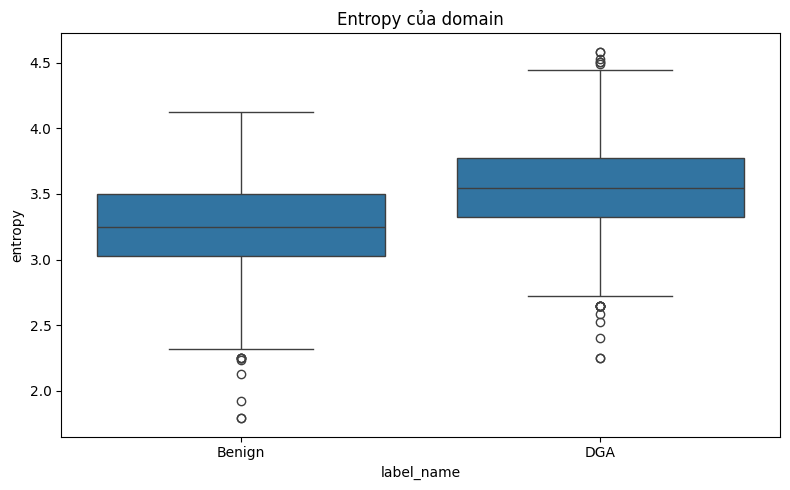

In [35]:
# 9. So sánh entropy
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="label_name", y="entropy")
plt.title("Entropy của domain")
plt.tight_layout()
plt.show()


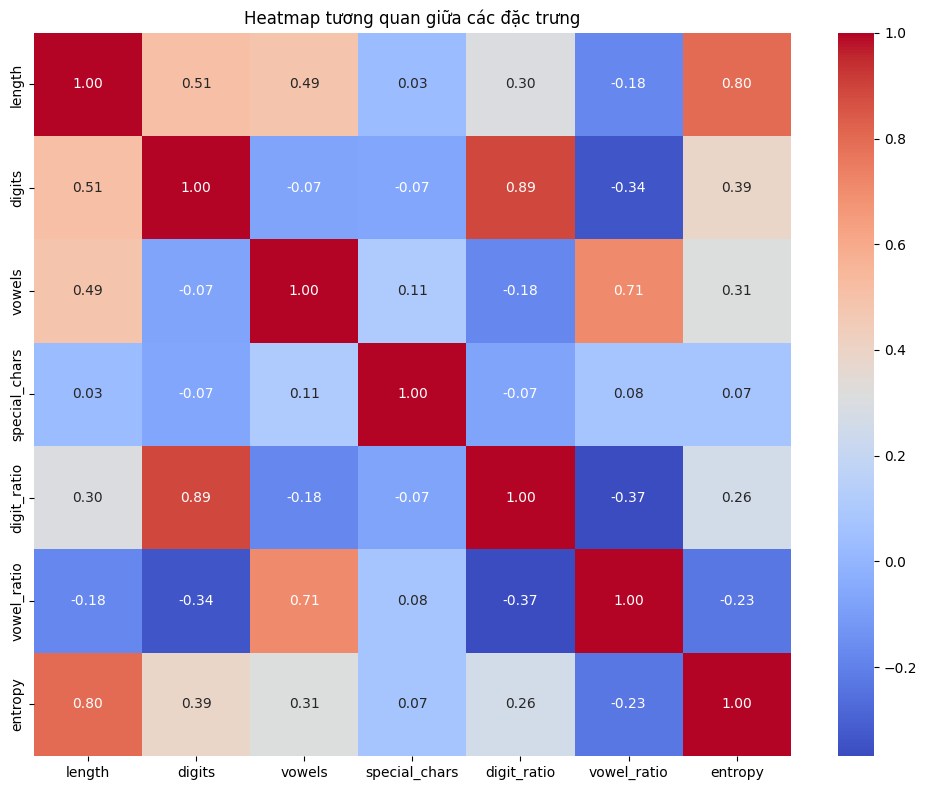

In [36]:
# 10. Heatmap tương quan các đặc trưng
corr = df[feature_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap tương quan giữa các đặc trưng")
plt.tight_layout()
plt.show()

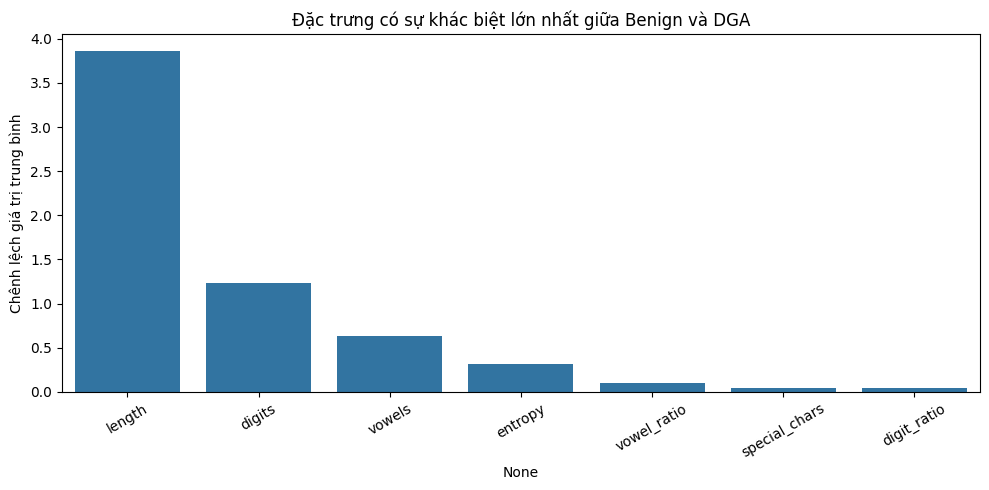

In [37]:
# 11. Đặc trưng có sự khác biệt lớn nhất giữa Benign và DGA
mean_features = df.groupby("label_name")[feature_cols].mean().T
mean_features["diff"] = abs(mean_features["DGA"] - mean_features["Benign"])
mean_features = mean_features.sort_values("diff", ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x=mean_features.index, y=mean_features["diff"])
plt.xticks(rotation=30)
plt.title("Đặc trưng có sự khác biệt lớn nhất giữa Benign và DGA")
plt.ylabel("Chênh lệch giá trị trung bình")
plt.tight_layout()
plt.show()

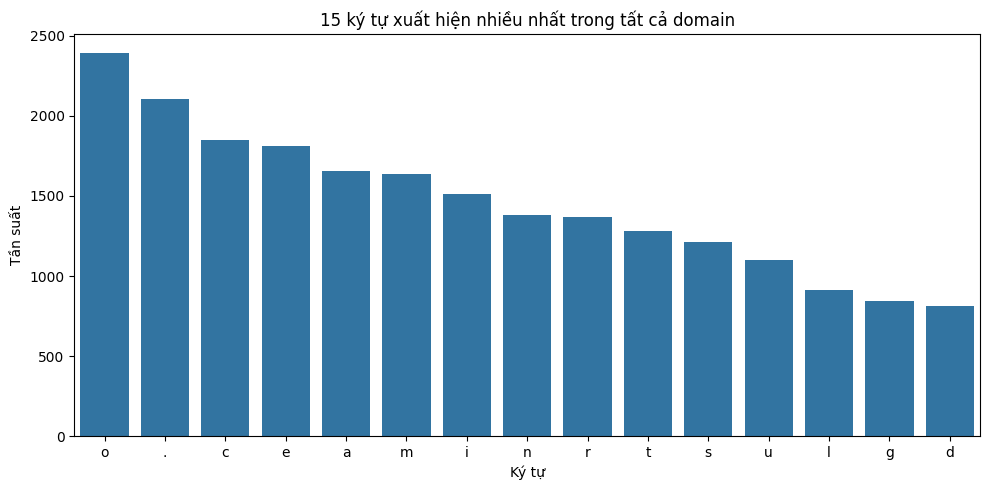

In [38]:
# 12. Top ký tự xuất hiện nhiều nhất trong domain
all_chars = "".join(df["domain"])
counter = Counter(all_chars)
top_chars = counter.most_common(15)

plt.figure(figsize=(10,5))
sns.barplot(x=[c[0] for c in top_chars], y=[c[1] for c in top_chars])
plt.title("15 ký tự xuất hiện nhiều nhất trong tất cả domain")
plt.xlabel("Ký tự")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.show()